# MLP, backpropagation и dropout

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "03_mlp_dropout"
OUT.mkdir(exist_ok=True, parents=True)

## Нейрон, XOR и проверка autograd

Проверяю формулу нейрона, XOR и производную через центральную разность. Затем сравниваю MLP с линейной моделью на make_moons.

Нейрон: 7.450580596923828e-09 autograd: 2.0 численная: 1.9999973333376018


XOR: {'accuracy': 1.0, 'macro_f1': 1.0}
Линейный baseline validation accuracy: 0.8541666666666666


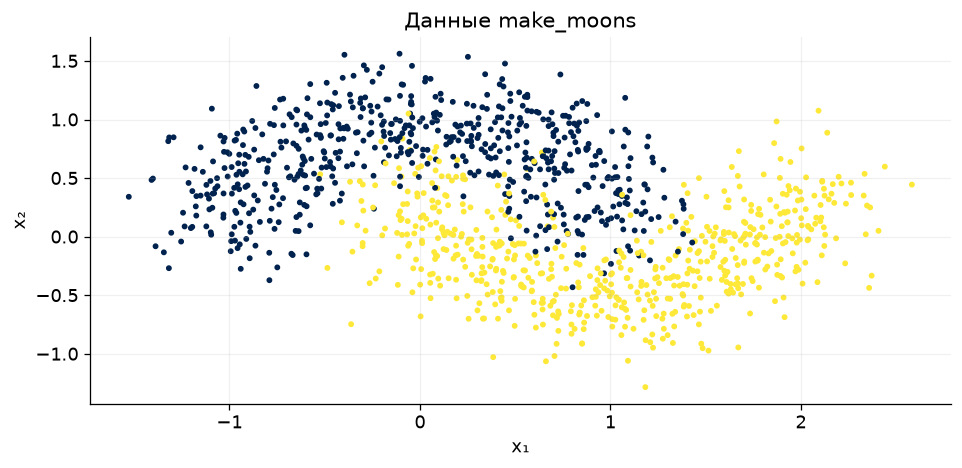

In [2]:
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression

x = torch.tensor([[1.0, 2.0]])
w = torch.tensor([[0.3], [-0.2]], requires_grad=True)
b = torch.tensor(0.1, requires_grad=True)
a = torch.tanh(x @ w + b)
a.backward()
eps = 1e-3


def f(v):
    return math.tanh(0.3 + 2 * v + 0.1)


print(
    "Нейрон:",
    a.item(),
    "autograd:",
    w.grad[1].item(),
    "численная:",
    (f(-0.2 + eps) - f(-0.2 - eps)) / (2 * eps),
)
xx = tensor([[-1, -1], [-1, 1], [1, -1], [1, 1]])
yy = tensor([0, 1, 1, 0], True)
seed_all()
xor = MLP(2, 2, (8,))
xor, h, _ = fit(xor, (xx, yy), (xx, yy), epochs=350, lr=0.03, batch=4)
print("XOR:", classify(xor, (xx, yy))[0])
X, y = make_moons(1200, noise=0.24, random_state=11)
train, val, test = split3(X, y)
base = LogisticRegression().fit(train[0], train[1])
print("Линейный baseline validation accuracy:", base.score(val[0], val[1]))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="cividis", s=7)
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("Данные make_moons")
showfig("data", OUT)

## Вариант 11. Пять уровней dropout

p = 0, 0.1, 0.3, 0.5 и 0.7. Два скрытых слоя по 64 нейрона, ReLU. Данные и остальные параметры одинаковые. Режимы train/eval проверяю на одном batch.

,dropout,accuracy,macro_f1,seconds,train_loss,val_loss
0,0.0,0.93750,0.93750,0.45911,0.11454,0.17616
1,0.1,0.94583,0.94582,0.50687,0.11663,0.17719
2,0.3,0.93750,0.93750,0.50419,0.11562,0.18781
3,0.5,0.94167,0.94167,0.50440,0.12198,0.19931
4,0.7,0.93750,0.93750,0.50060,0.13208,0.20653


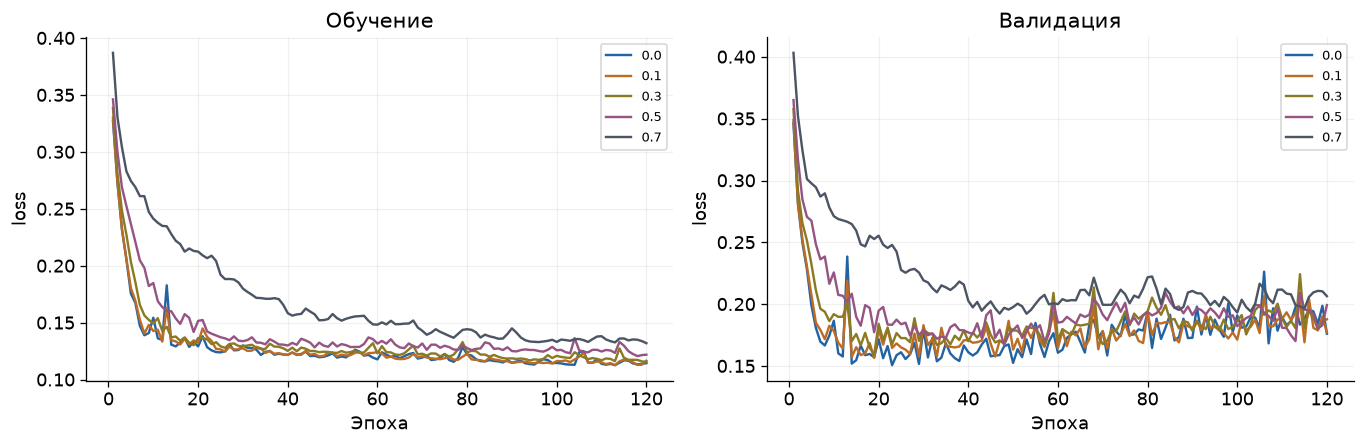

Test: {'accuracy': 0.95, 'macro_f1': 0.95}


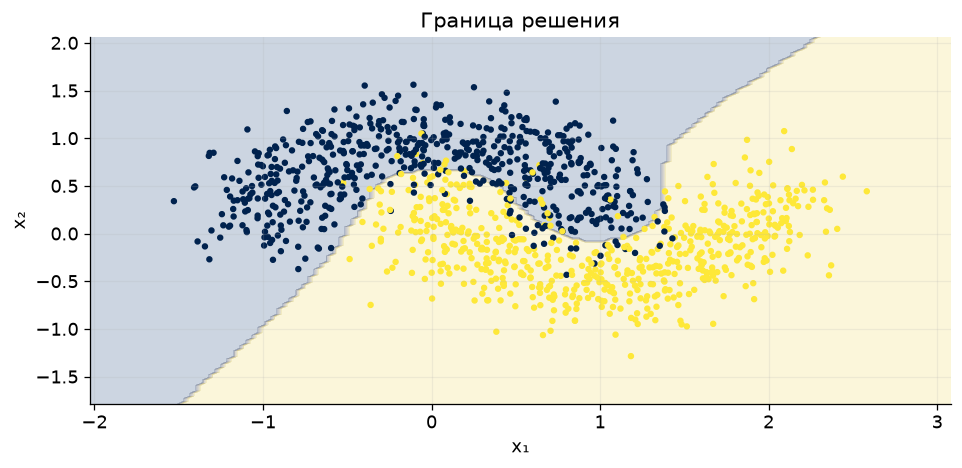

,index,true,predicted,confidence,probability_margin,analysis
0,15,1,0,0.90156,0.80311,Уверенная ошибка: проверить неоднозначность пр...
1,53,0,1,0.90525,0.81050,Уверенная ошибка: проверить неоднозначность пр...
2,57,1,0,0.83100,0.66201,Уверенная ошибка: проверить неоднозначность пр...
3,96,0,1,0.55391,0.10782,Ошибка при близких вероятностях классов
4,103,1,0,0.94596,0.89192,Уверенная ошибка: проверить неоднозначность пр...
5,136,1,0,0.99920,0.99840,Уверенная ошибка: проверить неоднозначность пр...
6,140,0,1,0.91495,0.82989,Уверенная ошибка: проверить неоднозначность пр...
7,159,0,1,0.73384,0.46768,Уверенная ошибка: проверить неоднозначность пр...
8,169,1,0,0.93957,0.87915,Уверенная ошибка: проверить неоднозначность пр...
9,178,0,1,0.53736,0.07471,Ошибка при близких вероятностях классов


Ошибки классификации. Большая уверенность ошибочного ответа указывает на ограничение калибровки; близкие признаки классов усложняют границу.

Средняя дисперсия train: 0.009759689 eval: 2.583874e-14


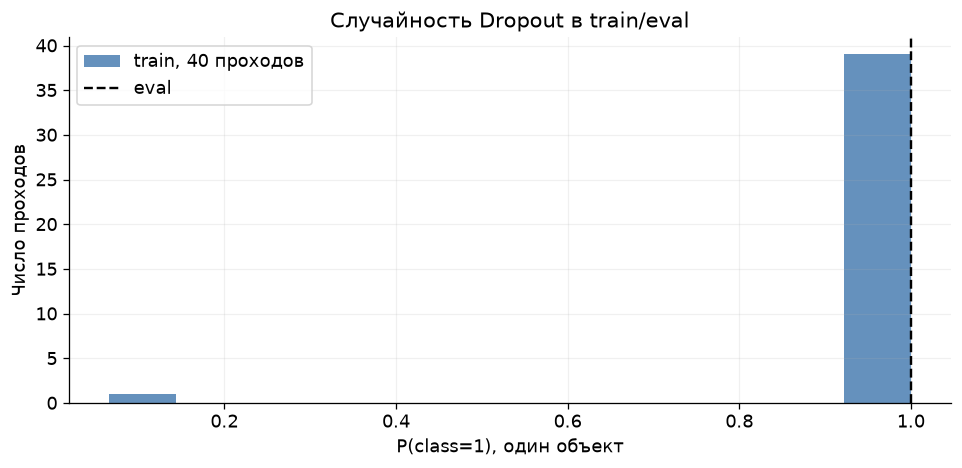

На этой validation-выборке лучший macro-F1 у p=0.1. В train dropout случайно зануляет активации с масштабированием 1/(1−p); в eval используется вся сеть. Сильный dropout может ухудшить оптимизацию и вызвать недообучение. Лучший p зависит от данных и выбранной архитектуры.

In [3]:
rows = []
curves = {}
models = {}
for p in [0.0, 0.1, 0.3, 0.5, 0.7]:
    seed_all()
    m = MLP(2, 2, (64, 64), dropout=p)
    m, h, t = fit(m, train, val, epochs=120, lr=0.005)
    metrics, _, _ = classify(m, val)
    rows.append(
        {
            "dropout": p,
            **metrics,
            "seconds": t,
            "train_loss": h.iloc[-1].train_loss,
            "val_loss": h.iloc[-1].val_loss,
        }
    )
    curves[str(p)] = h
    models[p] = m
df = table(rows, OUT)
histories(curves, OUT)
bestp = float(df.sort_values("macro_f1", ascending=False).iloc[0].dropout)
m = models[bestp]
print("Test:", classify(m, test)[0])
boundary(m, X, y, OUT)
errors(m, test, OUT)
stochastic = models[0.5]
xb = val[0][:64]
stochastic.train()
with torch.no_grad():
    pt = torch.stack([stochastic(xb).softmax(1) for _ in range(40)]).numpy()
stochastic.eval()
with torch.no_grad():
    pe = torch.stack([stochastic(xb).softmax(1) for _ in range(40)]).numpy()
print("Средняя дисперсия train:", pt.var(0).mean(), "eval:", pe.var(0).mean())
assert pe.var(0).max() < 1e-10
plt.hist(pt[:, 0, 1], bins=12, alpha=0.7, label="train, 40 проходов")
plt.axvline(pe[0, 0, 1], ls="--", color="black", label="eval")
plt.xlabel("P(class=1), один объект")
plt.ylabel("Число проходов")
plt.title("Случайность Dropout в train/eval")
plt.legend()
showfig("train_eval", OUT)
note(
    f"На этой validation-выборке лучший macro-F1 у p={bestp}. В train dropout случайно зануляет активации с масштабированием 1/(1−p); в eval используется вся сеть. Сильный dropout может ухудшить оптимизацию и вызвать недообучение. Лучший p зависит от данных и выбранной архитектуры."
)
torch.save(m.state_dict(), OUT / "best_model.pt")

## Глубина, активации и нормы градиентов

Отдельно сравниваю глубину, активации и величину градиентов.

In [4]:
rows = []
for act, depth in [("relu", 1), ("relu", 4), ("tanh", 4)]:
    seed_all()
    m = MLP(2, 2, (32,) * depth, activation=act)
    m, h, t = fit(m, train, val, epochs=80, lr=0.005)
    m.zero_grad()
    nn.functional.cross_entropy(m(train[0][:128]), train[1][:128]).backward()
    norms = [
        p.grad.norm().item()
        for name, p in m.named_parameters()
        if name.endswith("weight")
    ]
    metrics, _, _ = classify(m, val)
    rows.append(
        {
            "activation": act,
            "depth": depth,
            **metrics,
            "gradient_norms": str(np.round(norms, 5)),
        }
    )
table(rows, OUT, "depth_activation")
note(
    "Мёртвые ReLU имеют нулевые производные на отрицательных входах. Tanh ограничивает активации и может насыщаться. Численная производная проверяет локальную чувствительность, autograd вычисляет её цепным правилом по графу."
)

,activation,depth,accuracy,macro_f1,gradient_norms
0,relu,1,0.94167,0.94166,[0.07268 0.04533]
1,relu,4,0.94583,0.94582,[0.15847 0.24783 0.0693 0.03886 0.0591 ]
2,tanh,4,0.94167,0.94166,[0.16188 0.25992 0.16281 0.05214 0.0463 ]


Мёртвые ReLU имеют нулевые производные на отрицательных входах. Tanh ограничивает активации и может насыщаться. Численная производная проверяет локальную чувствительность, autograd вычисляет её цепным правилом по графу.

## Ответы на контрольные вопросы

1. Без нелинейной активации композиция аффинных слоёв остаётся аффинной.

2. Backpropagation вычисляет градиенты функции потерь по узлам графа и параметрам с помощью цепного правила.

3. Сравнить autograd с центральной разностью (L(θ+ε)−L(θ−ε))/(2ε), отключив случайные слои и проверив несколько ε.

4. Одинаковые начальные веса сохраняют симметрию скрытых нейронов и мешают им учить разные признаки.

5. Loss — значение функции; градиент — её чувствительность к параметрам; оптимизатор использует градиент для обновления весов.